# 04 · Customer Support: response, resolution, SLA & satisfaction

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200); pd.set_option("display.float_format", "{:,.2f}".format)
from src.data_cleaning.loader import load_all_processed, load_all_raw
from src.kpi.kpis import kpi_by, compute_all_kpis
from src.analytics import eda
d = load_all_processed()
t, f, o, c = d["tickets_enriched"], d["customer_feedback"], d["operations"], d["customers"]
VIS = ROOT / "visualizations"
def show(*names):
    for n in names: display(Image(filename=str(VIS / f"{n}.png"), width=820))

In [2]:
cols = ["tickets","avg_frt_h","avg_resolution_h","median_resolution_h","sla_compliance_pct","fcr_pct","escalation_pct","reopen_pct","avg_csat"]
for dim in ["support_channel", "ticket_priority", "department_name", "ticket_category"]:
    display(Markdown(f"### By {dim}")); display(kpi_by(t, dim)[[dim] + cols])

### By support_channel

,support_channel,tickets,avg_frt_h,avg_resolution_h,median_resolution_h,sla_compliance_pct,fcr_pct,escalation_pct,reopen_pct,avg_csat
0,Email,"7,885.00",10.29,44.26,30.79,63.21,13.57,10.25,8.47,3.47
1,Live Chat,"5,849.00",0.13,23.03,11.70,84.33,29.49,10.21,8.39,4.13
2,Phone,"5,283.00",0.08,20.78,10.08,85.96,32.97,10.37,7.92,4.16
3,Social Media,"1,684.00",7.53,44.11,29.82,65.33,14.50,9.99,7.73,3.37
4,Unknown,120.00,3.85,33.68,18.88,69.30,14.04,11.30,8.77,3.53
5,Web Portal,"3,179.00",13.47,48.69,34.95,58.55,11.37,10.07,8.74,3.32


### By ticket_priority

,ticket_priority,tickets,avg_frt_h,avg_resolution_h,median_resolution_h,sla_compliance_pct,fcr_pct,escalation_pct,reopen_pct,avg_csat
0,Critical,"1,655.00",2.87,11.44,7.03,54.69,9.75,18.87,9.79,3.56
1,High,"5,980.00",3.76,21.20,14.96,69.37,16.18,14.88,8.88,3.68
2,Low,"6,875.00",7.93,48.94,34.41,78.27,26.50,5.75,7.75,3.83
3,Medium,"9,490.00",5.95,36.39,25.38,74.47,23.28,9.03,8.11,3.78


### By department_name

,department_name,tickets,avg_frt_h,avg_resolution_h,median_resolution_h,sla_compliance_pct,fcr_pct,escalation_pct,reopen_pct,avg_csat
0,Billing & Accounts,"4,885.00",6.12,35.88,22.89,73.73,20.61,9.48,9.59,3.73
1,Customer Success,"2,344.00",5.62,23.88,13.19,83.07,28.98,10.84,6.41,3.75
2,Logistics & Delivery,"2,719.00",5.69,43.39,31.26,63.85,14.23,10.97,7.98,3.61
3,Order Management,"3,084.00",5.79,20.80,13.67,88.22,31.28,5.39,4.54,4.00
4,Returns & Refunds,"2,832.00",5.99,59.75,42.03,50.00,10.63,10.91,14.58,3.55
5,Technical Support,"8,136.00",5.51,30.03,19.11,74.71,22.36,11.84,7.46,3.79


### By ticket_category

,ticket_category,tickets,avg_frt_h,avg_resolution_h,median_resolution_h,sla_compliance_pct,fcr_pct,escalation_pct,reopen_pct,avg_csat
0,Account Access,"2,578.00",5.80,12.16,6.80,95.85,43.10,3.91,3.43,4.18
1,Billing & Payment,"4,885.00",6.12,35.88,22.89,73.73,20.61,9.48,9.59,3.73
2,Complaint,976.00,4.92,41.25,29.36,64.20,6.76,23.54,12.87,3.26
3,Delivery Problem,"2,719.00",5.69,43.39,31.26,63.85,14.23,10.97,7.98,3.61
4,Order Status,"3,084.00",5.79,20.80,13.67,88.22,31.28,5.39,4.54,4.00
5,Product Inquiry,"1,368.00",6.12,11.49,6.36,96.53,44.84,1.79,1.81,4.15
6,Returns & Refunds,"2,832.00",5.99,59.75,42.03,50.00,10.63,10.91,14.58,3.55
7,Technical Issue,"5,558.00",5.38,38.37,26.89,64.85,12.69,15.54,9.34,3.62


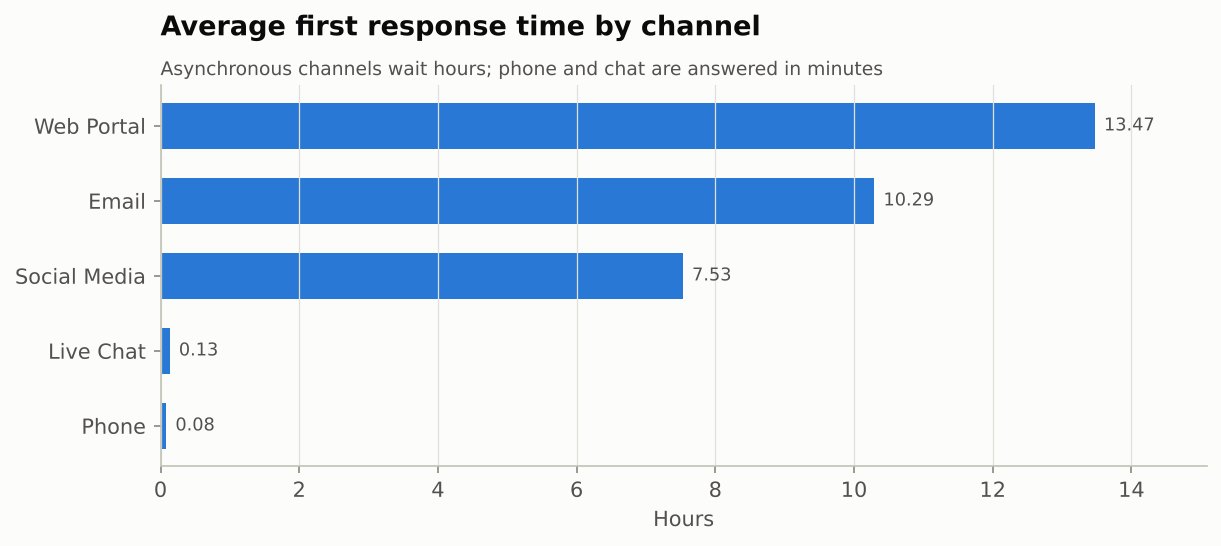

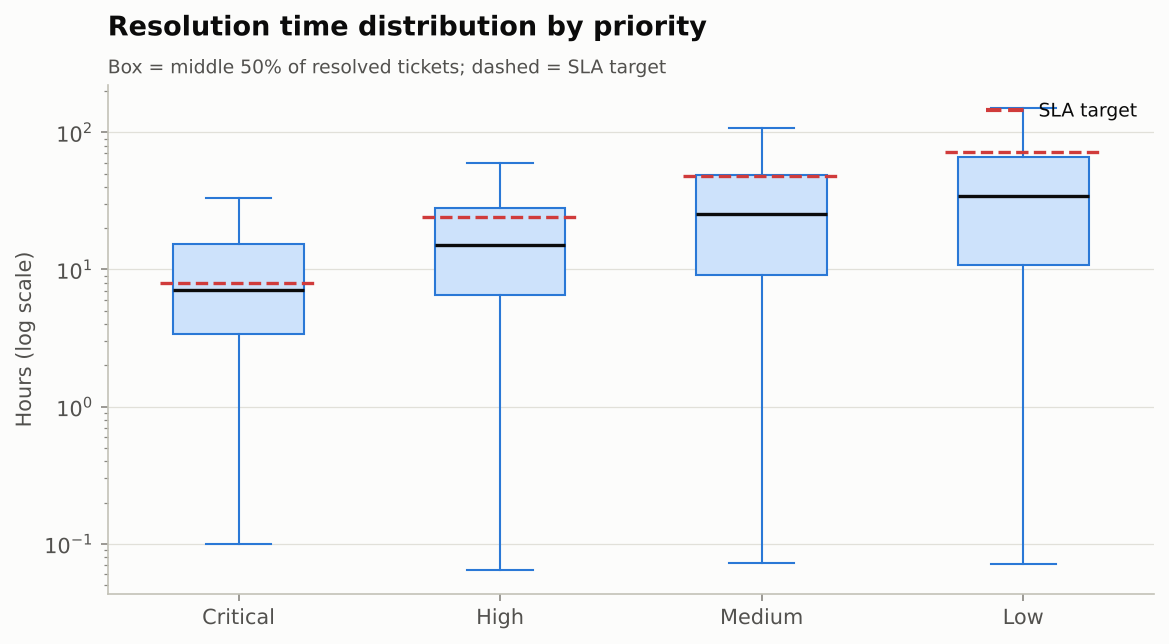

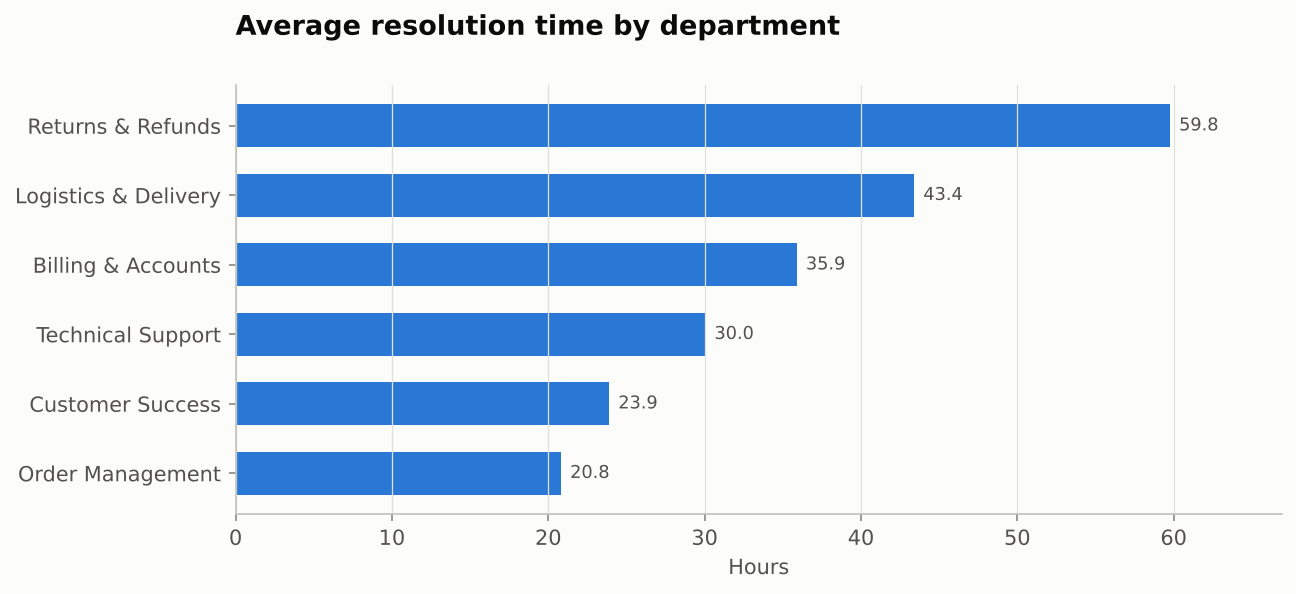

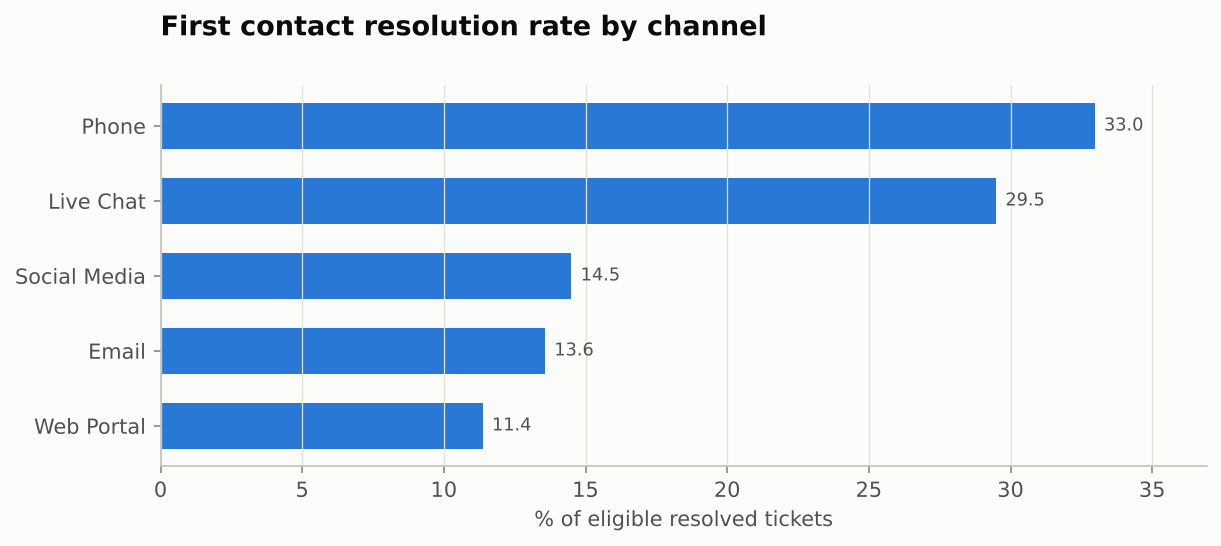

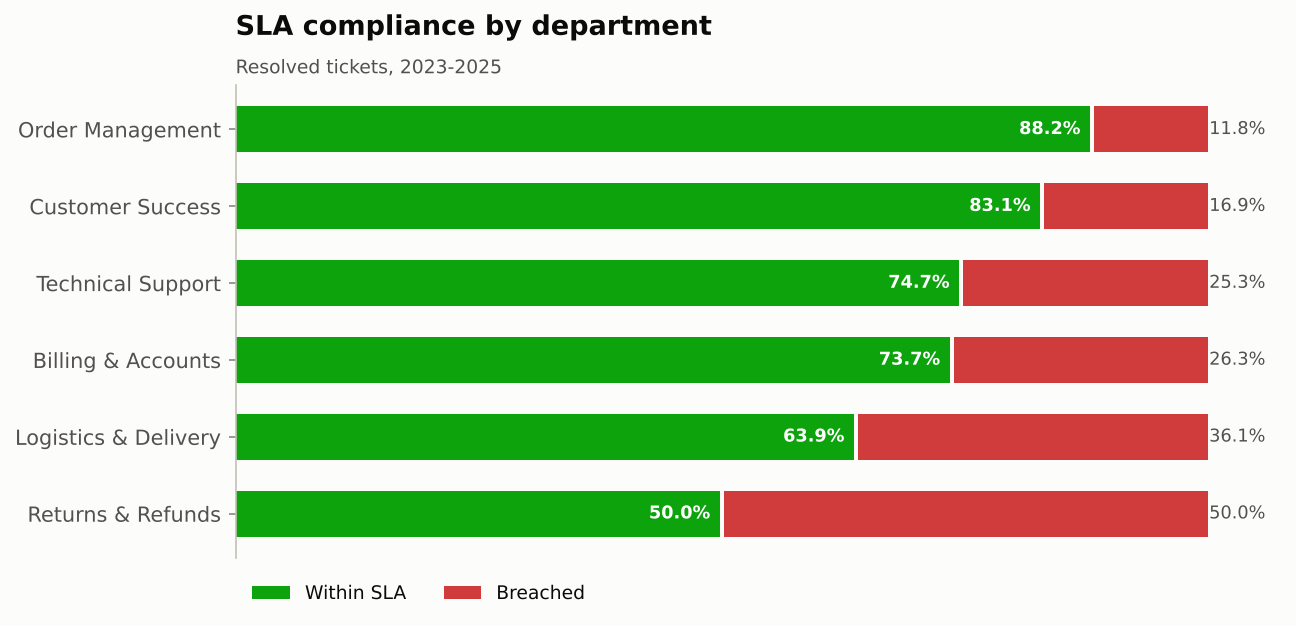

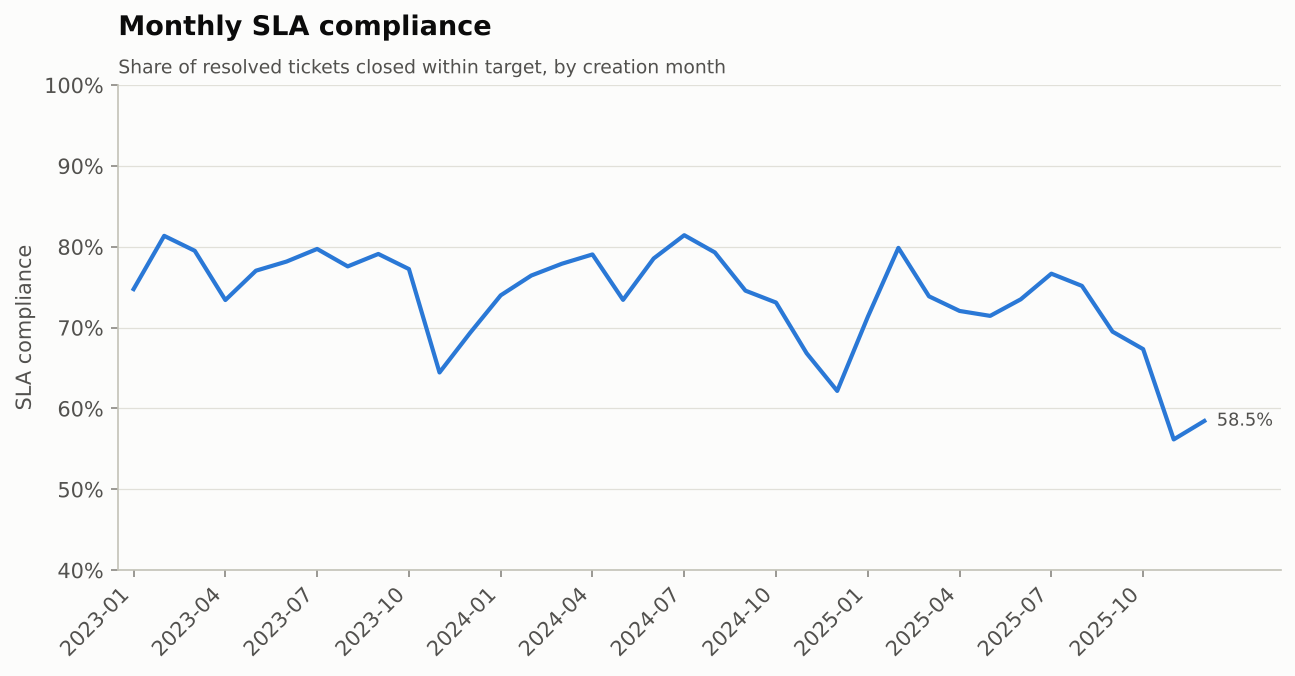

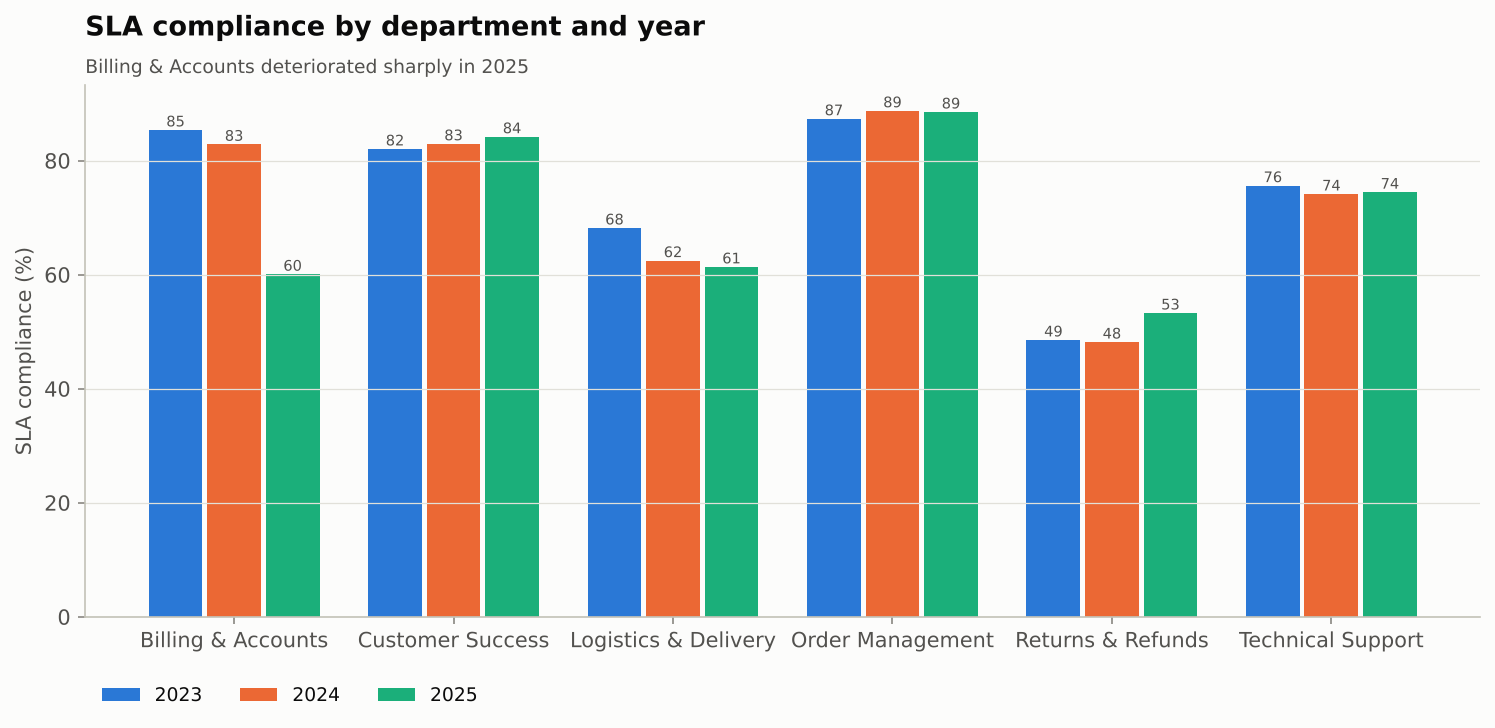

In [3]:
show("16_frt_by_channel", "17_resolution_by_priority", "18_resolution_by_department", "21_fcr_by_channel", "22_sla_by_department", "23_sla_trend", "24_sla_by_department_year")

## Backlog and aging

,aging_bucket,open_tickets
0,0-2 days,35
1,3-7 days,18
2,8-14 days,19
3,15-30 days,30
4,31-60 days,45
5,60+ days,110


ticket_status,In Progress,Open,Pending
ticket_priority,,,
Critical,9,4,5
High,21,10,14
Medium,51,14,35
Low,43,16,35


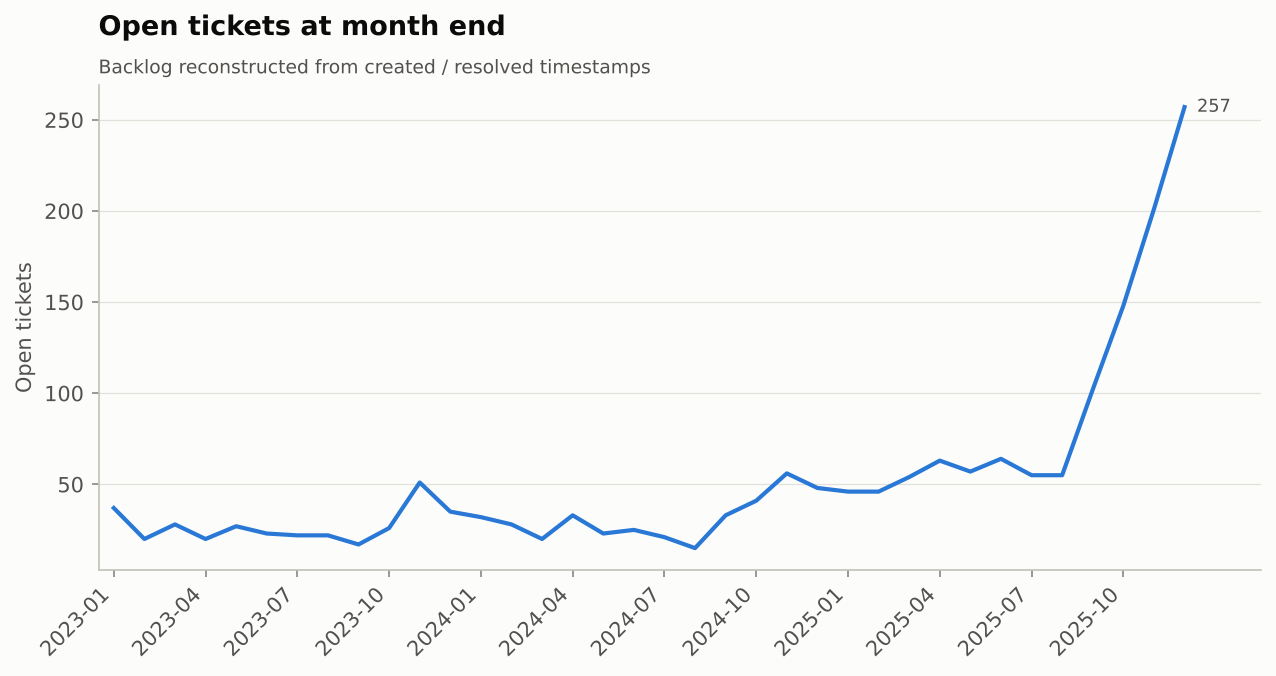

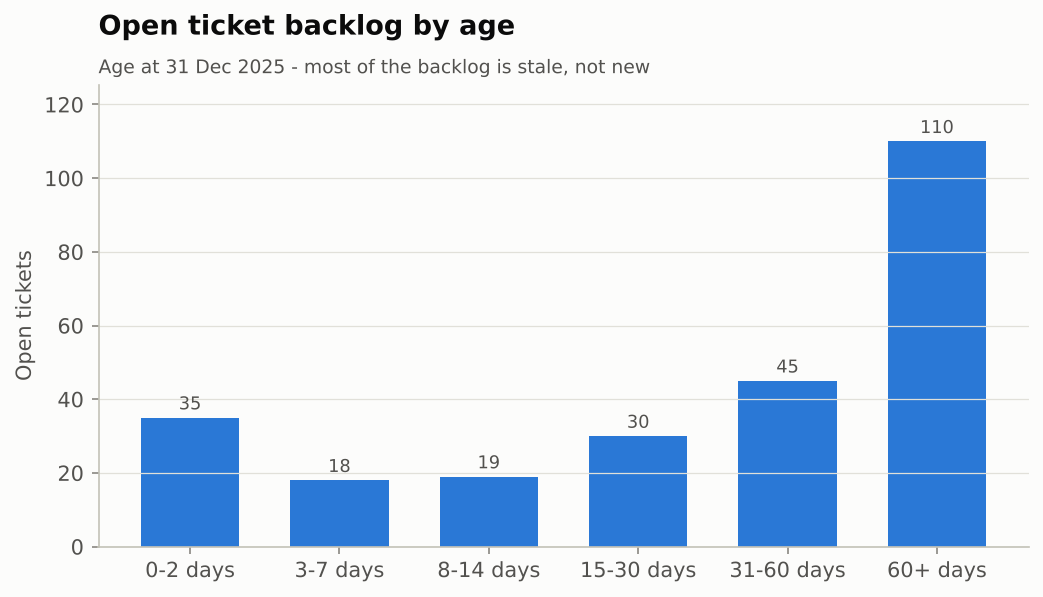

In [4]:
display(eda.backlog_aging(t)); display(eda.backlog_by_status_priority(t))
show("15_backlog_trend", "20_backlog_aging")

## Satisfaction

,frt_bucket,surveys,avg_csat,csat_rate_pct
0,<15 min,5132,4.14,79.89
1,15-60 min,842,3.98,72.33
2,1-4 h,1765,3.65,59.26
3,4-8 h,1493,3.50,53.52
4,8-24 h,2263,3.30,44.14
5,24 h+,769,2.95,29.00


,sla_outcome,surveys,avg_csat,csat_rate_pct
0,SLA breached,3870,2.79,17.88
1,Within SLA,8431,4.19,84.28


,feedback_category,responses,avg_csat
0,Response Speed,3718,3.22
1,Agent Professionalism,2683,4.17
2,Resolution Quality,2472,3.98
3,Communication,1968,4.09
4,Product Issue,1086,3.76
5,Process & Policy,539,3.03


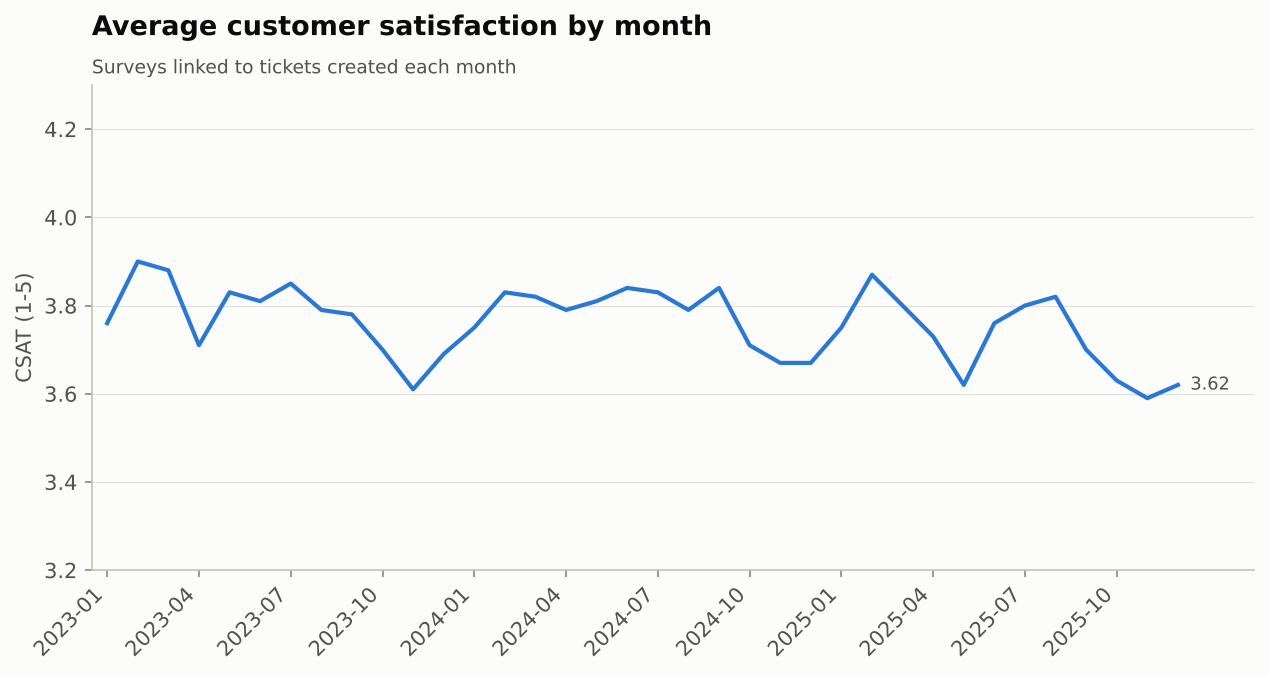

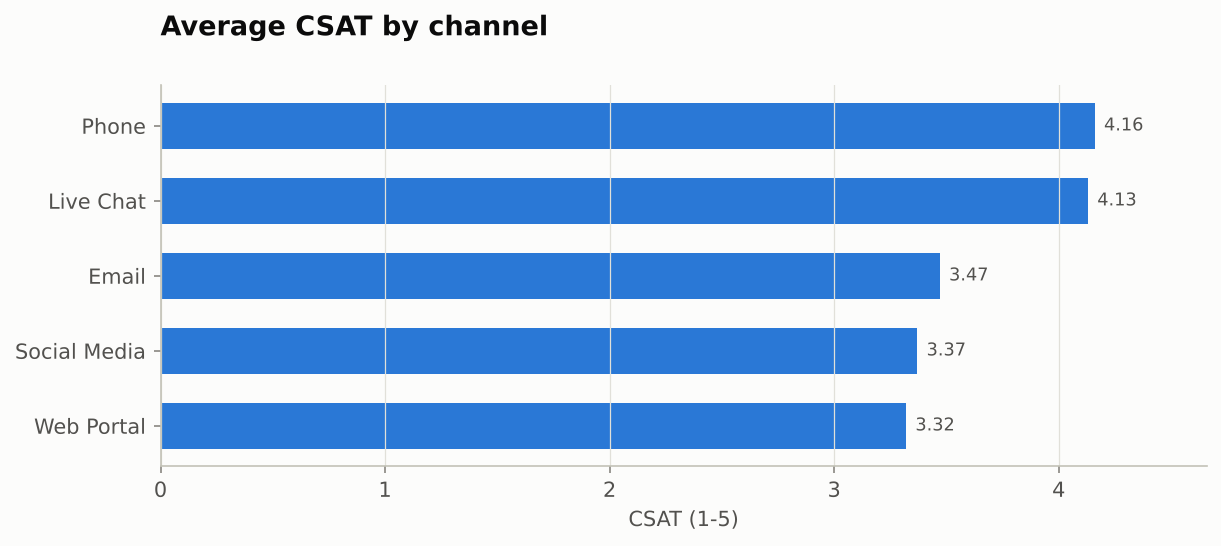

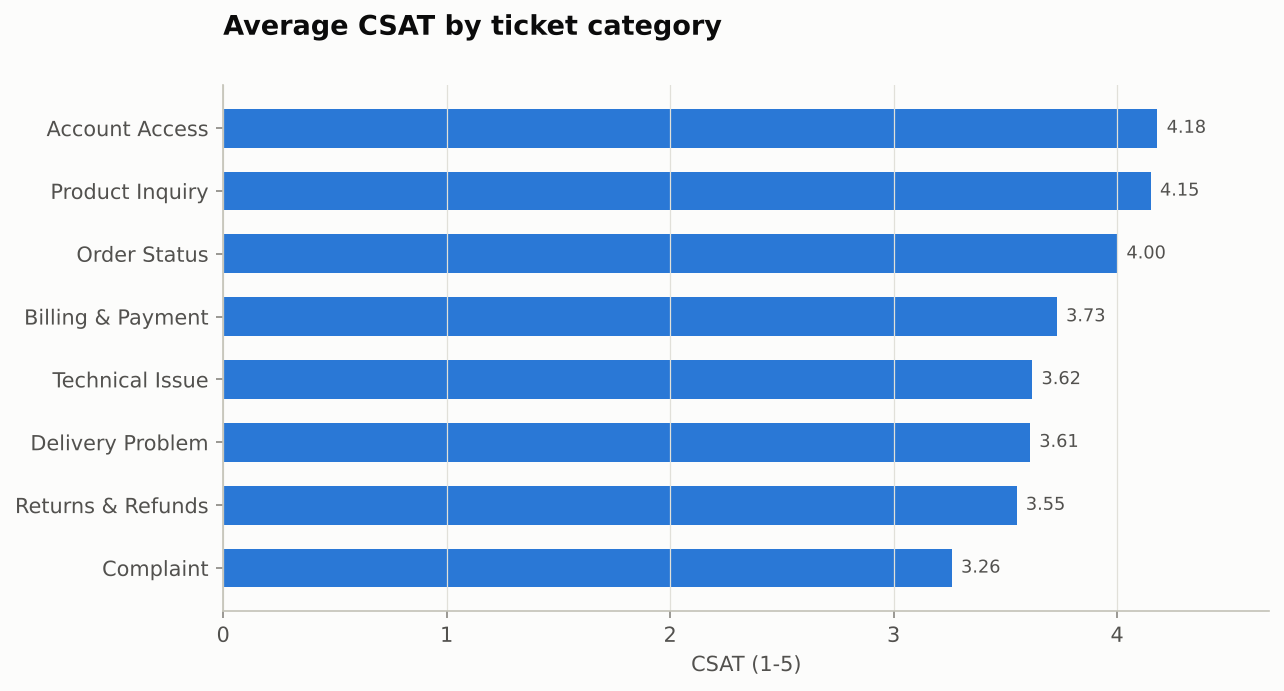

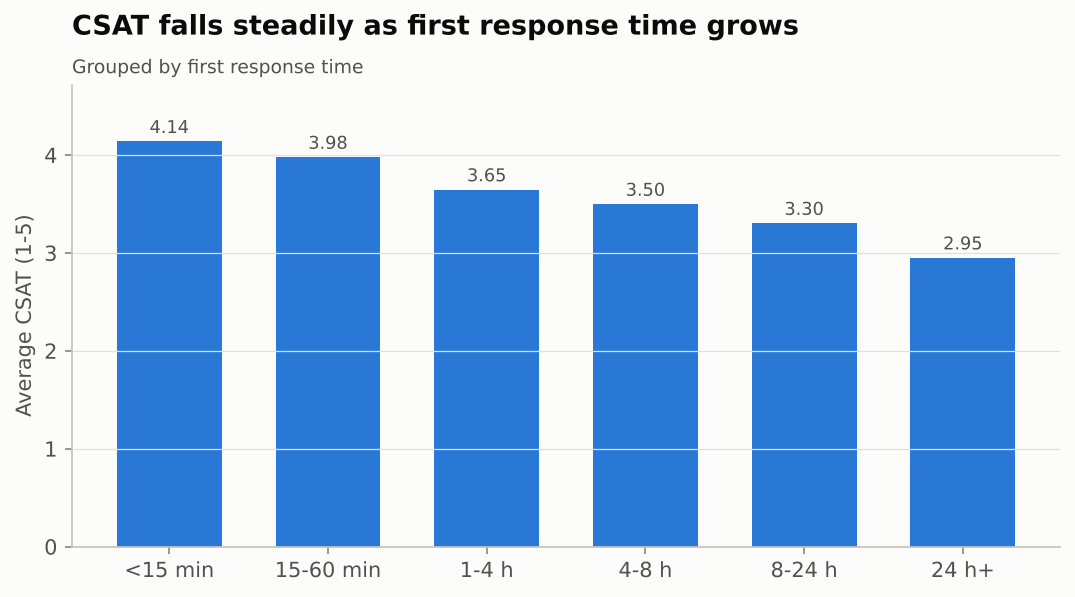

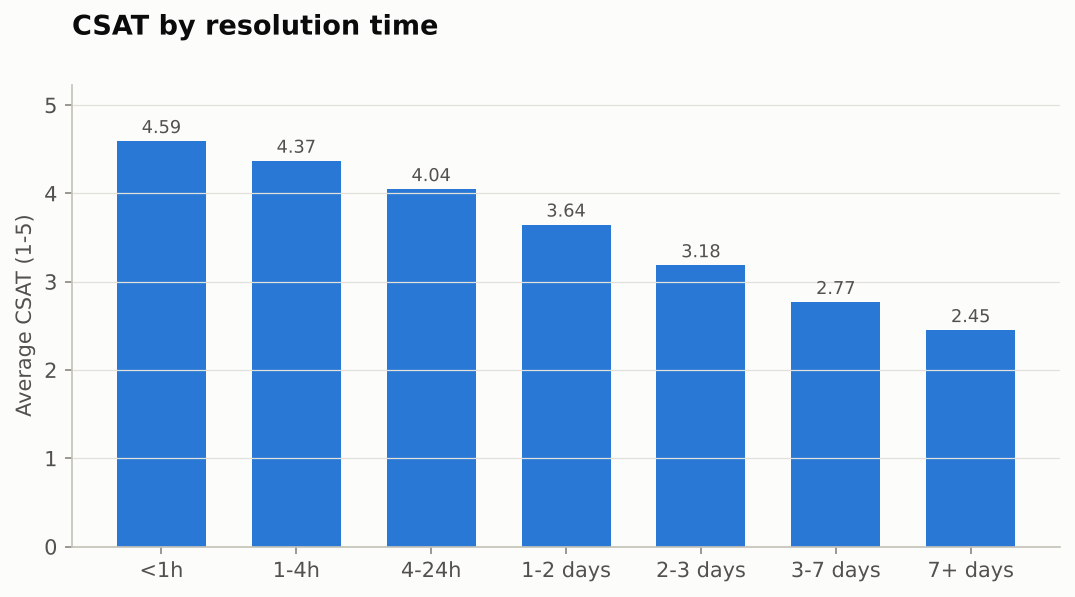

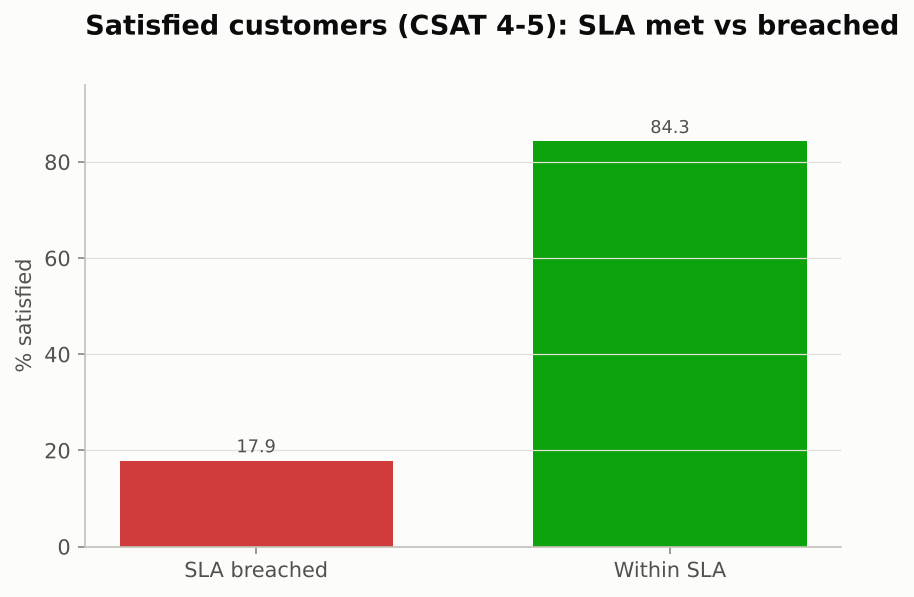

In [5]:
display(eda.frt_bucket_csat(t)); display(eda.sla_met_csat(t)); display(eda.feedback_categories(f))
show("25_csat_trend", "26_csat_by_channel", "27_csat_by_category", "30_csat_vs_first_response", "31_csat_vs_resolution", "32_csat_sla_outcome")

## Observations (seed 42)
* **Channel is the biggest service divider**: Email/Web Portal/Social answer in hours (≈7-13 h) while Phone/Chat answer in minutes; SLA compliance is ~59-65% vs ~84-86%.
* **Returns & Refunds** is the weakest department (50% SLA, ~60 h average resolution, highest reopen rate).
* **Billing & Accounts** fell from ~83-85% SLA compliance (2023-2024) to ~60% in 2025.
* **Critical** tickets have the *lowest* SLA compliance (~55%) despite top priority.
* CSAT drops monotonically with first response time (4.14 → 2.95), and an SLA breach is associated with a ~1.4 point lower CSAT.
* 60% of the open backlog is older than 30 days: the backlog is stale, not fresh demand.